The previous chapters were about the protein target. Now we turn to the other half of drug discovery: the **small molecule** that will become the drug. **Cheminformatics** is computing with molecules, representing them, measuring their properties, comparing them, and searching libraries of millions for promising ones. It is the foundation for the activity prediction (chapter 14) and docking (chapter 15) that follow. We work throughout with **RDKit**, the standard open-source chemistry toolkit, on a real dataset: every small-molecule drug ever approved.

:::eli5
A molecule is a specific arrangement of atoms and bonds. To compute with millions of them, we need to turn each into something a computer handles easily: first a short text string (a recipe for the molecule), then a "fingerprint", a long list of yes/no answers to "does it contain this little piece?". Two molecules with similar fingerprints are built from similar pieces, and, remarkably often, do similar things in the body. That one fact, similar molecules behave similarly, is the engine of computational drug discovery.
:::

## Molecules as strings: SMILES

A molecule's 2D structure (which atoms, which bonds) is captured by a compact text string called **SMILES**. Atoms are their element letters, bonds are implied or marked (`=` double, `#` triple), rings are opened and closed with matching digits, and branches use parentheses. `CCO` is ethanol; `CC(=O)O` is acetic acid; aspirin is `CC(=O)OC1=CC=CC=C1C(=O)O`. RDKit parses SMILES into a molecule object you can compute on.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, AllChem, DataStructs, Crippen, Lipinski
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

drugs = pd.read_csv("datasets/chembl_approved_small_molecules.csv").dropna(subset=["smiles"])
drugs["mol"] = drugs["smiles"].apply(Chem.MolFromSmiles)
drugs = drugs[drugs["mol"].notna()].reset_index(drop=True)
print(f"{len(drugs)} approved small-molecule drugs parsed from SMILES")

aspirin = Chem.MolFromSmiles("CC(=O)OC1=CC=CC=C1C(=O)O")
print(f"aspirin: {aspirin.GetNumAtoms()} heavy atoms, {aspirin.GetNumBonds()} bonds, canonical SMILES {Chem.MolToSmiles(aspirin)}")
R["n_drugs"] = len(drugs)

3311 approved small-molecule drugs parsed from SMILES
aspirin: 13 heavy atoms, 13 bonds, canonical SMILES CC(=O)Oc1ccccc1C(=O)O


:::bio
SMILES is not the only representation. **InChI** is a canonical identifier (every molecule has exactly one) good for database lookup; **SMARTS** is a pattern language for substructure search ("find molecules containing a carboxylic acid"); and **molecular graphs** (atoms as nodes, bonds as edges) are the input to modern **graph neural networks** for molecules. 3D coordinates add stereochemistry and conformation, which matter for binding (chapter 15). A drug is also chiral: the same 2D structure can be a life-saving drug or useless (or harmful) in its mirror image.
:::

## Molecular descriptors: numbers from structure

A **descriptor** is any number computed from a molecule's structure: molecular weight, lipophilicity (logP, prerequisite P2), number of hydrogen-bond donors and acceptors, polar surface area, number of rotatable bonds, ring count. These few numbers predict a lot about how a molecule behaves as a drug, they are the basis of Lipinski's rule of five (prerequisite P13). Let's compute them for every approved drug and see the chemical space they occupy.

          MW  logP   HBD   HBA    TPSA  RotB  rings  heavy
mean   406.4   2.0   2.2   5.3    99.6   5.7    2.9   27.4
min      4.0 -24.1   0.0   0.0     0.0   0.0    0.0    1.0
max   3061.6  13.5  36.0  52.0  1122.0  60.0   19.0  200.0


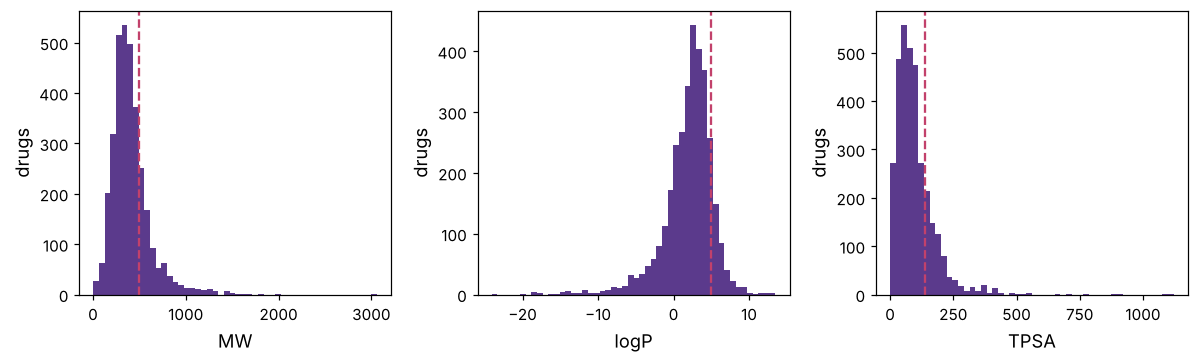

In [2]:
def descriptors(mol):
    return {
        "MW": Descriptors.MolWt(mol), "logP": Crippen.MolLogP(mol),
        "HBD": Lipinski.NumHDonors(mol), "HBA": Lipinski.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol), "RotB": Descriptors.NumRotatableBonds(mol),
        "rings": Descriptors.RingCount(mol), "heavy": mol.GetNumHeavyAtoms(),
    }

desc = pd.DataFrame([descriptors(m) for m in drugs["mol"]])
print(desc.describe().loc[["mean", "min", "max"]].round(1).to_string())

fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, cut in [(axs[0], "MW", 500), (axs[1], "logP", 5), (axs[2], "TPSA", 140)]:
    ax.hist(desc[col], bins=50, color="#5b3a8c"); ax.axvline(cut, color="#c2416b", ls="--")
    ax.set_xlabel(col); ax.set_ylabel("drugs")
save_fig("descriptors"); plt.show()
R["mean_mw"] = f"{desc.MW.mean():.0f}"; R["mean_logp"] = f"{desc.logP.mean():.1f}"

![Figure 13-1. Distributions of three key descriptors across approved drugs, with common drug-likeness thresholds (dashed). Most drugs cluster below molecular weight 500 and logP 5, Lipinski's limits.](images/descriptors.png)

Approved drugs average about 406 Da and logP 2.0, squarely in drug-like space. Descriptors are the simplest **features** for machine learning on molecules, and the playground's second tab lets you plot drugs in any two of them and see the drug-like region.

::playground animations/chem_lab.html 640

## Fingerprints: molecules as bit-vectors

Descriptors are a handful of numbers; they throw away most of the structure. To compare molecules by their actual substructure, we use a **fingerprint**: a long bit-vector where each bit marks the presence of a particular small fragment. The popular **Morgan (ECFP) fingerprint** enumerates the circular neighbourhood around each atom out to a given radius and hashes each into a bit. Two molecules sharing many fragments share many bits.

In [3]:
def morgan_fp(mol, radius=2, n_bits=2048):
    return AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)

fp_aspirin = morgan_fp(aspirin)
print(f"Morgan fingerprint: {fp_aspirin.GetNumBits()} bits, {fp_aspirin.GetNumOnBits()} set for aspirin")
# which fragments? (bit -> substructure count)
fps = [morgan_fp(m) for m in drugs["mol"]]
bits_per_drug = [fp.GetNumOnBits() for fp in fps]
print(f"typical drug sets {np.median(bits_per_drug):.0f} of 2048 bits")
R["aspirin_bits"] = fp_aspirin.GetNumOnBits()

Morgan fingerprint: 2048 bits, 24 set for aspirin
typical drug sets 43 of 2048 bits


## Chemical similarity: the Tanimoto coefficient

The standard measure of similarity between two fingerprints is the **Tanimoto coefficient**: the number of bits set in both, divided by the number set in either. It runs from 0 (nothing in common) to 1 (identical fingerprints).

:::math
$$T(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{\text{bits set in both}}{\text{bits set in } A \text{ or } B}.$$
A Tanimoto above ~0.7 (on Morgan fingerprints) usually means closely related molecules; below ~0.3, unrelated. The exact threshold depends on the fingerprint.
:::

In [4]:
def tanimoto(m1, m2):
    return DataStructs.TanimotoSimilarity(morgan_fp(m1), morgan_fp(m2))

named = {name: Chem.MolFromSmiles(drugs[drugs.name == name].iloc[0].smiles)
         for name in ["IMATINIB", "NILOTINIB", "MORPHINE", "CODEINE", "ASPIRIN", "PARACETAMOL", "CAFFEINE"]
         if (drugs.name == name).any()}
pairs = [("MORPHINE", "CODEINE"), ("IMATINIB", "NILOTINIB"), ("ASPIRIN", "PARACETAMOL"), ("IMATINIB", "CAFFEINE")]
for a, b in pairs:
    if a in named and b in named:
        print(f"Tanimoto({a}, {b}) = {tanimoto(named[a], named[b]):.2f}")
R["morph_cod"] = f"{tanimoto(named['MORPHINE'], named['CODEINE']):.2f}" if "MORPHINE" in named and "CODEINE" in named else "NA"

Tanimoto(MORPHINE, CODEINE) = 0.76
Tanimoto(IMATINIB, NILOTINIB) = 0.52
Tanimoto(IMATINIB, CAFFEINE) = 0.10


The numbers match chemical intuition: **morphine and codeine** (codeine is morphine with one methyl added) score 0.76; **imatinib and nilotinib** (two drugs for the same leukaemia, deliberately related) score around 0.5; **imatinib and caffeine** (unrelated) score near 0.1. The playground's first tab lets you pick any drug and rank the others by similarity to it.

## Similarity search: finding leads

The "similar molecules, similar activity" principle powers **similarity search**: given a molecule known to be active, scan a huge library for the most similar ones as candidate leads. Let's search all approved drugs for the closest relatives of a query, imatinib, the pioneering leukaemia drug (prerequisite P12).

In [5]:
query = Chem.MolFromSmiles(drugs[drugs.name == "IMATINIB"].iloc[0].smiles)
query_fp = morgan_fp(query)
sims = DataStructs.BulkTanimotoSimilarity(query_fp, fps)
drugs["sim_to_imatinib"] = sims
top = drugs.sort_values("sim_to_imatinib", ascending=False).head(8)[["name", "sim_to_imatinib"]]
print("most similar approved drugs to imatinib:")
print(top.to_string(index=False))
R["top_sim_name"] = top.iloc[1]["name"]; R["top_sim_val"] = f"{top.iloc[1]['sim_to_imatinib']:.2f}"

most similar approved drugs to imatinib:
                               name  sim_to_imatinib
                           IMATINIB         1.000000
                  IMATINIB MESYLATE         0.942029
                          NILOTINIB         0.516854
NILOTINIB HYDROCHLORIDE MONOHYDRATE         0.505495
                          PONATINIB         0.397959
            PONATINIB HYDROCHLORIDE         0.393939
                        MOMELOTINIB         0.379310
        MOMELOTINIB DIHYDROCHLORIDE         0.375000


The search surfaces other **kinase inhibitors** (imatinib's drug class), because they share imatinib's scaffold. In real discovery this is run against libraries of millions to billions of purchasable or virtual molecules; the hits become the starting points for the activity models of chapter 14. Similarity search is also how patents are checked and how "me-too" drugs are found.

## Clustering chemical space

With fingerprints and a similarity measure, we can **cluster** a library into families of related molecules, useful for picking a diverse screening set (one representative per cluster) or organising results. Let's cluster a sample of drugs and visualise the chemical space in 2D.

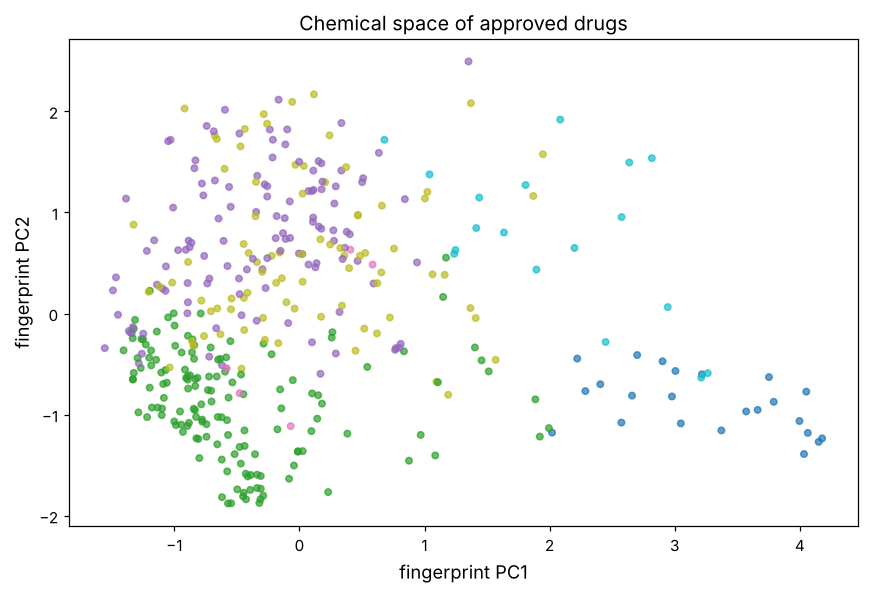

In [6]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# fingerprint matrix for a sample, reduced to 2D
sample = drugs.sample(400, random_state=0).reset_index(drop=True)
X = np.array([list(morgan_fp(m)) for m in sample["mol"]], dtype=float)
coords = PCA(n_components=2, random_state=0).fit_transform(X)
clusters = KMeans(n_clusters=6, random_state=0, n_init=10).fit_predict(X)

fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=clusters, cmap="tab10", s=18, alpha=0.7)
# label a few well-known drugs if present
for name in ["ASPIRIN", "MORPHINE", "ATORVASTATIN", "PACLITAXEL", "CAFFEINE", "IMATINIB"]:
    if (sample.name == name).any():
        i = sample.index[sample.name == name][0]
        ax.annotate(name, coords[i], fontsize=9, fontweight="bold")
ax.set_xlabel("fingerprint PC1"); ax.set_ylabel("fingerprint PC2"); ax.set_title("Chemical space of approved drugs")
save_fig("chemical_space"); plt.show()

![Figure 13-2. A 2D map of 400 approved drugs by fingerprint similarity, coloured by cluster. Structurally related drugs group together; the map spreads from simple small molecules to large complex natural products.](images/chemical_space.png)

## Filtering: from millions to a shortlist

Real screening libraries contain millions of molecules, many of them junk, reactive, unstable, or likely to interfere with assays. Before expensive analysis, cheminformatics **filters** them:

- **Drug-likeness** (Lipinski, prerequisite P13) removes molecules unlikely to be oral drugs.
- **PAINS** (pan-assay interference compounds) flags notorious substructures that give false positives in many assays.
- **Reactive/toxic groups** are removed with substructure (SMARTS) patterns.
- **Synthetic accessibility** scores how hard a molecule would be to make.

In [7]:
from rdkit.Chem import FilterCatalog
params = FilterCatalog.FilterCatalogParams()
params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog.FilterCatalog(params)

def lipinski_pass(d):
    return (int(d["MW"] > 500) + int(d["logP"] > 5) + int(d["HBD"] > 5) + int(d["HBA"] > 10)) <= 1

lip = desc.apply(lipinski_pass, axis=1)
pains = np.array([catalog.HasMatch(m) for m in drugs["mol"]])
print(f"of {len(drugs)} approved drugs: {lip.mean():.0%} pass Lipinski, {100*pains.mean():.1f}% match a PAINS pattern")
R["lip_pass"] = f"{lip.mean():.0%}"; R["pains"] = f"{pains.mean():.1%}"

of 3311 approved drugs: 86% pass Lipinski, 5.6% match a PAINS pattern


Even among *approved* drugs, 86% satisfy Lipinski and only 5.6% hit a PAINS alert, a reassuring sanity check on the filters (approved drugs should mostly be clean). Applied to a raw screening library, these filters routinely discard the majority before any modelling, concentrating effort on plausible molecules.

:::idea
Filters are heuristics, not laws. Every rule has important exceptions among real drugs: large natural products (paclitaxel, prerequisite P7), antibiotics, and the growing class of "beyond rule of five" drugs. A filter that is too strict throws away good molecules; too loose, and you waste effort on bad ones. The art is using filters to triage, not to decide, and always checking what you are discarding. The same caution as the honest-ML discipline of chapter 8 applies here.
:::

## Summary

| Idea | One line |
|---|---|
| SMILES | compact text representation of a molecule's 2D structure |
| Descriptor | a number computed from structure (MW, logP, HBD, …) |
| Fingerprint | bit-vector marking which substructures a molecule contains |
| Tanimoto | similarity of two fingerprints; >0.7 is closely related |
| Similarity search | find library molecules similar to a known active |
| Clustering | group a library into structural families |
| Filtering | remove non-drug-like, reactive or interfering molecules |

:::check
1. What does the SMILES string `CC(=O)O` represent? *(Acetic acid.)*
2. What is the difference between a molecular descriptor and a fingerprint? *(A descriptor is a single number; a fingerprint is a bit-vector of substructure presence.)*
3. Two molecules have a Tanimoto of 0.85. What does that suggest? *(They are closely related and likely to have similar activity.)*
4. Why run a similarity search? *(To find new candidate molecules similar to a known active one.)*
5. Why filter a screening library before modelling? *(To remove non-drug-like, reactive or assay-interfering molecules and focus effort.)*
:::

:::exercise
Build a tiny similarity-search engine and test the "similar activity" principle indirectly. (a) Pick a drug class present in the data, say the statins (names ending in "STATIN"). (b) For each statin, find its nearest neighbour among all drugs by Tanimoto. (c) How often is the nearest neighbour another statin? What does that hit rate tell you about using similarity to group drugs by mechanism, and where would it fail?
:::

<details><summary>Solution</summary>

In [8]:
statins = drugs[drugs.name.str.contains("STATIN", na=False)]
print(f"{len(statins)} statins found:", list(statins.name))
hits = 0
for idx, row in statins.iterrows():
    sims = DataStructs.BulkTanimotoSimilarity(fps[idx], fps)
    sims[idx] = -1                                           # exclude itself
    nearest = drugs.iloc[int(np.argmax(sims))]
    same_class = "STATIN" in str(nearest["name"])
    hits += same_class
    print(f"  {row['name']:16s} -> {nearest['name']:16s} ({max(sims):.2f}) {'[statin]' if same_class else ''}")
print(f"nearest neighbour is another statin: {hits}/{len(statins)}")

19 statins found: ['LOVASTATIN', 'PRAVASTATIN SODIUM', 'CILASTATIN', 'SIMVASTATIN', 'PRAVASTATIN', 'CERIVASTATIN', 'ATORVASTATIN CALCIUM', 'ATORVASTATIN', 'ROSUVASTATIN', 'PENTOSTATIN', 'CERIVASTATIN SODIUM', 'CILASTATIN SODIUM', 'PITAVASTATIN', 'PITAVASTATIN CALCIUM', 'ROSUVASTATIN CALCIUM', 'FLUVASTATIN SODIUM', 'FLUVASTATIN', 'PITAVASTATIN SODIUM', 'PITAVASTATIN MAGNESIUM']
  LOVASTATIN       -> SIMVASTATIN      (0.74) [statin]
  PRAVASTATIN SODIUM -> PRAVASTATIN      (0.84) [statin]
  CILASTATIN       -> CILASTATIN SODIUM (0.83) [statin]
  SIMVASTATIN      -> LOVASTATIN       (0.74) [statin]
  PRAVASTATIN      -> PRAVASTATIN SODIUM (0.84) [statin]
  CERIVASTATIN     -> CERIVASTATIN SODIUM (0.84) [statin]
  ATORVASTATIN CALCIUM -> ATORVASTATIN     (0.86) [statin]
  ATORVASTATIN     -> ATORVASTATIN CALCIUM (0.86) [statin]
  ROSUVASTATIN     -> ROSUVASTATIN CALCIUM (0.84) [statin]
  PENTOSTATIN      -> DECITABINE       (0.48) 
  CERIVASTATIN SODIUM -> CERIVASTATIN     (0.84) [statin]


Most statins find another statin as their nearest neighbour, because they share the same core scaffold that binds the cholesterol-making enzyme (prerequisite P13). This is the "similar structure, similar activity" principle working: similarity search groups a mechanism class well when the class is defined by a common scaffold. It fails in two situations: **scaffold hops** (different structures that hit the same target, which similarity misses, a false negative) and **activity cliffs** (nearly identical molecules with very different activity, where one small change flips binding, a false positive). Those failures are exactly why we need the quantitative activity models of chapter 14 rather than similarity alone.

</details>